# FMCW LiDAR: chirps, Doppler and coherent detection

A frequency modulated continuous wave (FMCW) LiDAR does not time a pulse.
It sweeps the frequency of a narrow line laser linearly, sends most of
the light to the target and keeps a little as a **local oscillator**
(LO). The echo returns with the frequency the laser had a round trip
time $\tau = 2R/c$ ago; mixed with the LO on a photodiode, it beats at
the difference frequency

$$
f_b = \kappa\,\tau = \frac{B}{T}\,\frac{2R}{c},
$$

for a sweep of bandwidth $B$ in the time $T$. A Fourier transform of the
beat turns frequency into range, and a moving target adds its Doppler
shift $f_D = 2v/\lambda$, which an up and a down chirp separate from the
range. This is radar technology (automotive radars are FMCW) moved to
optical frequencies, where 1 m/s is a Doppler shift of 1.3 MHz.

Coherent detection changes the noise budget completely compared with
the time-of-flight LiDAR of notebook 130 (time-of-flight LiDAR):
the strong LO amplifies the echo before any electronic noise is added,
so the receiver is limited by the shot noise of the LO, nearly one
detected photon per unit of SNR; and only light in the LO's spatial mode
and within the receiver bandwidth of its frequency mixes, so sunlight is
irrelevant. The price is a demanding laser: a linear sweep of a GHz,
a coherence length longer than twice the range, and the speckle of the
target, which a coherent receiver sees as fading.

The sections:

1. chirp and beat: range from the beat spectrum, range resolution c/(2B),
2. Doppler: triangular chirps, range and velocity together,
3. the coherent receiver: LO power, balanced detection, the shot noise
   limit and why sunlight does not matter,
4. speckle: one spatial mode, Rayleigh fading and detection probability,
5. laser linewidth: the coherence length and the range limit,
6. nonlinear chirps and their correction with a reference
   interferometer.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ncx2

from pyoptics import lidar
from pyoptics import sketch

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
C = lidar.C
t_start = time.time()

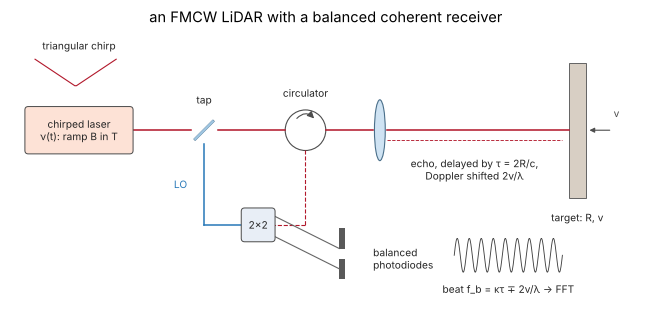

In [2]:
fig, ax = plt.subplots(figsize=(12, 4.5))
with sketch.text_scale(1.15):
    sketch.lidar_layout(ax, "fmcw", title="an FMCW LiDAR with a balanced coherent receiver")
plt.show()

## 1. Chirp and beat

The laser sweeps $B = 1$ GHz in $T = 10$ µs, a slope of
$\kappa = 10^{14}$ Hz/s: a target at 150 m (τ = 1 µs) beats at 100 MHz.
The receiver digitizes the complex (I/Q) beat at 500 MHz from 2 µs into
the ramp (when echoes from up to 300 m have arrived) to its end, and
transforms it with a Hann window. The frequency axis becomes a range
axis through $R = c f_b/(2\kappa)$.

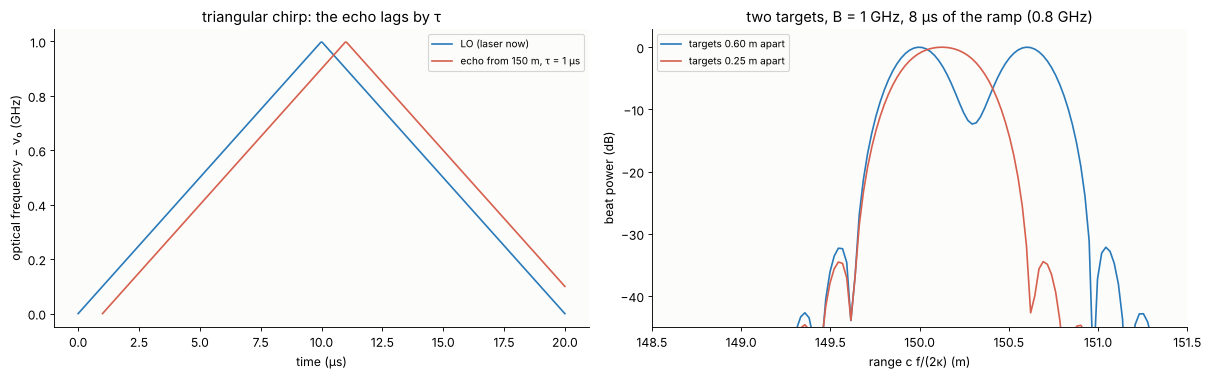

range resolution c/2B: 0.150 m for the full 1 GHz, 0.187 m for the 0.8 GHz used; with the Hann window about 0.37 m


In [3]:
B, T = 1e9, 10e-6
KAPPA = B/T
LAM = 1550e-9
FS = 500e6
t = 2e-6 + np.arange(int(8e-6*FS))/FS
N = len(t)
WIN = np.hanning(N)


def spectrum(b, pad=8):
    """Power spectrum of a complex beat (Hann window, zero padded), frequencies in Hz."""
    S = np.abs(np.fft.fftshift(np.fft.fft(b*WIN, pad*N)))**2/np.sum(WIN)**2
    f = np.fft.fftshift(np.fft.fftfreq(pad*N, 1/FS))
    return f, S


fig, axs = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
tt = np.linspace(0, 2*T, 400)
nu = np.where(tt < T, KAPPA*tt, KAPPA*(2*T - tt))
tau = 2*150/C
nu_e = np.where(tt - tau < T, KAPPA*(tt - tau), KAPPA*(2*T - tt + tau))
axs[0].plot(tt*1e6, nu/1e9, color=BLUE, label="LO (laser now)")
axs[0].plot(tt*1e6, np.where(tt > tau, nu_e, np.nan)/1e9, color=RED,
            label="echo from 150 m, τ = 1 µs")
axs[0].set_xlabel("time (µs)")
axs[0].set_ylabel("optical frequency − ν₀ (GHz)")
axs[0].set_title("triangular chirp: the echo lags by τ")
axs[0].legend(fontsize=9)

for (R1, R2), c in (((150.0, 150.6), BLUE), ((150.0, 150.25), RED)):
    b = lidar.fmcw_beat_signal(t, R1, B, T) + lidar.fmcw_beat_signal(t, R2, B, T)
    f, S = spectrum(b)
    r = C*f/(2*KAPPA)
    axs[1].plot(r, 10*np.log10(S/S.max()), color=c, label="targets {:.2f} m apart".format(R2 - R1))
axs[1].set_xlim(148.5, 151.5)
axs[1].set_ylim(-45, 3)
axs[1].set_xlabel("range c f/(2κ) (m)")
axs[1].set_ylabel("beat power (dB)")
axs[1].set_title("two targets, B = 1 GHz, 8 µs of the ramp (0.8 GHz)")
axs[1].legend(fontsize=9)
plt.show()
B_eff = KAPPA*N/FS
print("range resolution c/2B: {:.3f} m for the full 1 GHz, {:.3f} m for the 0.8 GHz used; "
      "with the Hann window about {:.2f} m".format(lidar.range_resolution(B), lidar.range_resolution(B_eff),
                                                  2*lidar.range_resolution(B_eff)))

The range resolution is $c/(2B)$, 15 cm for 1 GHz, exactly as for a pulse
of bandwidth $B$: what counts is the bandwidth, not how it is spent.
Only the part of the ramp after the echo has arrived is usable (here
0.8 GHz, 19 cm), and the Hann window, which keeps the side lobes of
strong targets below −30 dB, doubles the width of the peak: two
surfaces 60 cm apart are separated, 25 cm apart they merge into one
broadened peak. (A rectangular window would separate them, with side
lobes of −13 dB that hide weak targets next to strong ones.) Precision
is a different matter: a single strong peak can be located to a small
fraction of its width.

## 2. Doppler: range and velocity

A moving target shifts its echo by $f_D = 2v/\lambda$, 1.29 MHz per m/s
at 1550 nm. On an up chirp the beat becomes $\kappa\tau - f_D$, on a down
chirp $\kappa\tau + f_D$ (for an approaching target). Half the sum is the
range term, half the difference the Doppler term. A car at 150 m
approaching at 30 m/s (108 km/h) shifts by 39 MHz, the equivalent of
58 m of range on one ramp alone.

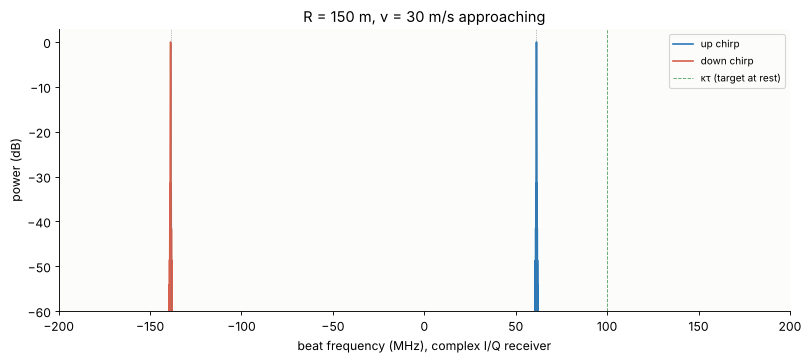

up 61.36 MHz, down 138.78 MHz -> R = 150.002 m, v = 30.001 m/s


In [4]:
R0, V0 = 150.0, 30.0
fig, ax = plt.subplots(figsize=(10, 4.4), layout="constrained")
peaks = {}
for down, c, name in ((False, BLUE, "up chirp"), (True, RED, "down chirp")):
    b = lidar.fmcw_beat_signal(t, R0, B, T, velocity=V0, wavelength=LAM, down=down)
    f, S = spectrum(b)
    ax.plot(f/1e6, 10*np.log10(S/S.max()), color=c, label=name)
    peaks[down] = f[np.argmax(S)]
f_up, f_down = lidar.fmcw_beat_frequencies(R0, B, T, V0, LAM)
for fx in (f_up, -f_down):
    ax.axvline(fx/1e6, color=GREY, lw=0.6, ls=":")
ax.axvline(KAPPA*2*R0/C/1e6, color=GREEN, lw=0.8, ls="--", label="κτ (target at rest)")
ax.set_xlim(-200, 200)
ax.set_ylim(-60, 3)
ax.set_xlabel("beat frequency (MHz), complex I/Q receiver")
ax.set_ylabel("power (dB)")
ax.set_title("R = 150 m, v = 30 m/s approaching")
ax.legend(fontsize=9)
plt.show()
R_est, v_est = lidar.fmcw_range_velocity(peaks[False], -peaks[True], B, T, LAM)
print("up {:.2f} MHz, down {:.2f} MHz -> R = {:.3f} m, v = {:.3f} m/s".format(
    peaks[False]/1e6, -peaks[True]/1e6, R_est, v_est))

The down chirp beats at negative frequencies (the echo is now *above*
the LO), which a complex I/Q receiver distinguishes; a real receiver
sees only $|f|$ and needs the sign from elsewhere. Every point of an
FMCW point cloud carries its radial velocity, measured to a few cm/s
from one up/down pair: moving objects are separated from the static
scene in a single frame, which a ToF LiDAR can only infer by comparing
frames. With several targets in one beam, the up and down peaks must be
paired; FMCW LiDARs use more chirp shapes, or two lasers chirping in
opposite directions at the same time.

## 3. The coherent receiver

On a balanced pair of photodiodes, the beat of an echo $P_s$ with the LO
$P_\mathrm{LO}$ gives a current of mean square $2R_d^2 P_s P_\mathrm{LO}$,
while the direct terms $R_d(P_s + P_\mathrm{LO})$ cancel between the two
diodes. The noise in the bandwidth $B_e$ is the shot noise of the LO,
$2qR_dP_\mathrm{LO}B_e$, the amplifier noise $i_n^2 B_e$, and the
relative intensity noise of the LO, which the balanced pair cancels to
its common mode rejection:

$$
\mathrm{SNR} = \frac{2R_d^2 P_s P_\mathrm{LO}}
{2qR_d(P_\mathrm{LO} + P_s)B_e + i_n^2 B_e + \epsilon\,(R_dP_\mathrm{LO})^2\,\mathrm{RIN}\,B_e}
\;\to\; \frac{R_d P_s}{q B_e} = \frac{\eta P_s}{h\nu B_e}.
$$

For a strong LO the SNR becomes the number of detected signal photons in
the time $1/B_e$: the **shot noise limit** of heterodyne detection. In an
FFT the bandwidth of one bin is the inverse of the record length, so
the SNR of a peak equals the number of signal photoelectrons in the
whole record.

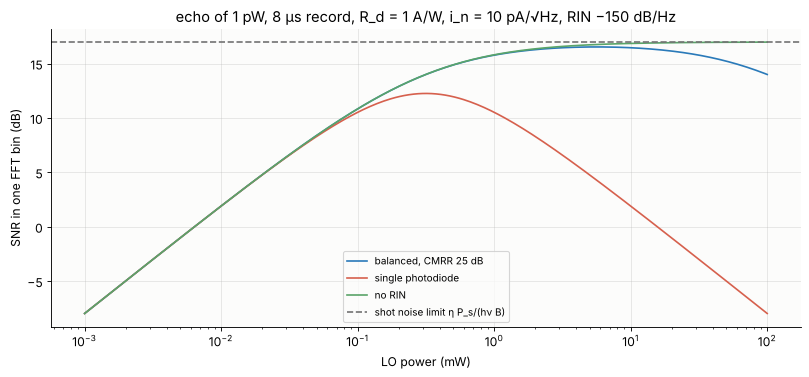

detected signal photons in 8 us: 49.9; shot noise limited SNR 17.0 dB
balanced receiver: best SNR 16.5 dB at 5.57 mW LO


In [5]:
P_lo = np.logspace(-6, -1, 300)
P_s = 1e-12
Be = 1/(N/FS)                     # one FFT bin
fig, ax = plt.subplots(figsize=(10, 4.6), layout="constrained")
limit = 0.8*P_s/(lidar.H*C/LAM*Be)
for kw, c, name in ((dict(balanced=True, cmrr_db=25), BLUE, "balanced, CMRR 25 dB"),
                    (dict(balanced=False), RED, "single photodiode"),
                    (dict(balanced=True, cmrr_db=25, rin_db=-200), GREEN, "no RIN")):
    snr = lidar.coherent_snr(P_s, P_lo, Be, 1.0, input_noise=10e-12, rin_db=kw.pop("rin_db", -150), **kw)
    ax.semilogx(P_lo*1e3, 10*np.log10(snr), color=c, label=name)
ax.axhline(10*np.log10(limit), color=GREY, ls="--", label="shot noise limit η P_s/(hν B)")
ax.set_xlabel("LO power (mW)")
ax.set_ylabel("SNR in one FFT bin (dB)")
ax.set_title("echo of 1 pW, 8 µs record, R_d = 1 A/W, i_n = 10 pA/√Hz, RIN −150 dB/Hz")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.show()
print("detected signal photons in 8 us: {:.1f}; shot noise limited SNR {:.1f} dB".format(
    limit, 10*np.log10(limit)))
best = lidar.coherent_snr(P_s, P_lo, Be, 1.0, input_noise=10e-12, rin_db=-150, balanced=True,
                          cmrr_db=25)
print("balanced receiver: best SNR {:.1f} dB at {:.2f} mW LO".format(10*np.log10(best.max()),
                                                                    P_lo[np.argmax(best)]*1e3))

With little LO power, the amplifier noise dominates; around 1 mW the
LO's shot noise takes over and the SNR approaches the shot noise limit,
here 50 detected photons from a 1 pW echo in 8 µs, 17 dB. More LO power
then helps nothing, and a single photodiode is ruined by the intensity
noise of the LO, which grows with the square of its power. The balanced
pair suppresses it: this is why every coherent receiver is balanced.

Sunlight does not enter this budget. It reaches the photodiodes like
any background, but it only adds its own shot noise, and that is tiny
against the shot noise of a milliwatt LO; and its beat with the LO is
spread over the whole optical bandwidth of the Sun. What mixes into the
receiver bandwidth is the sunlight in **one spatial mode** (the LO's)
and in the bandwidth $B_e$ around the LO frequency:

In [6]:
E_sun = lidar.solar_irradiance(1550.0)                     # W m^-2 nm^-1
# radiance of a white Lambertian surface in full sun, W m^-2 sr^-1 Hz^-1
L_nu = E_sun/np.pi*(1550e-9)**2/C*1e9
P_mode = L_nu*(1550e-9)**2*1e6                             # one mode (A Omega = lambda^2), 1 MHz
P_sun_dd = lidar.background_power(E_sun, 1.0, 0.025, 1e-3, 3.0)
print("white target in full sun: {:.1e} W in one spatial mode and 1 MHz "
      "({:.1e} photons/s), against {:.1e} W on a direct detector "
      "(25 mm, 1 mrad, 3 nm filter)".format(P_mode, lidar.photons(P_mode, 1550.0), P_sun_dd))

white target in full sun: 1.3e-18 W in one spatial mode and 1 MHz (1.0e+01 photons/s), against 8.0e-11 W on a direct detector (25 mm, 1 mrad, 3 nm filter)


About $10^{-18}$ W, ten photons per second, or one per FFT record of a
hundred thousand ramps: the coherent receiver is blind to the Sun, while
a direct detector of the same aperture collects almost $10^{-10}$ W. This is a property of the mode, not of
the filter: a single mode receiver has the étendue $\lambda^2$ and accepts
the brightness of a black body, never more (notebook 83, étendue). The same
property costs signal, as the next section shows.

## 4. Speckle: one mode, and fading

The target is rough on the scale of the wavelength. Its echo is a
speckle pattern; a coherent receiver measures the projection of the
returned field onto the LO mode, a sum of many random phasors from the
lit spot: a complex Gaussian amplitude, whose power is exponentially
distributed (**Rayleigh fading**). A monostatic coherent LiDAR whose
beam is diffraction limited by its aperture collects on average about
one speckle, and the mean heterodyne power is close to what a direct
detector of the same aperture would receive, but the individual
measurement fluctuates by 100 %.

Below a 1D model: a Gaussian beam lights a rough target, the backscattered
field is propagated back to the receiver aperture (a Fraunhofer
transform), and its overlap with the LO mode (the transmitted beam
itself) is compared with the total power in the aperture.

contrast of the heterodyne power: 0.97 (1 for Rayleigh fading)


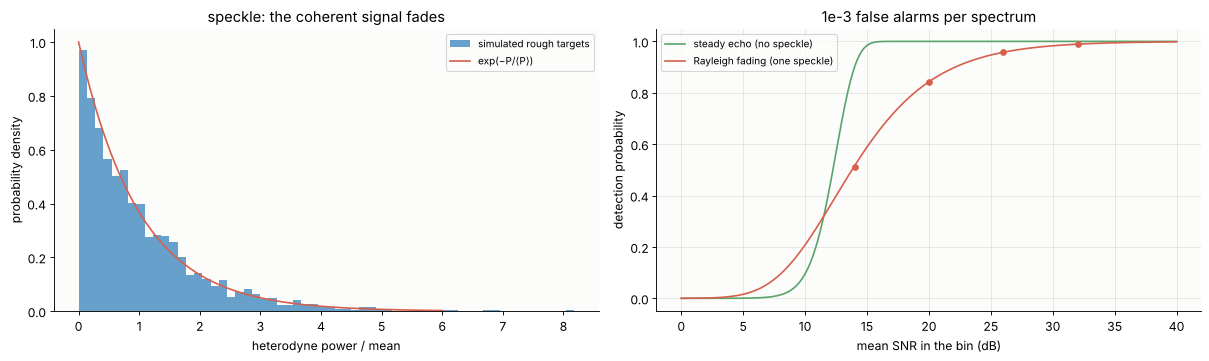

Pd = 90%: steady 14.0 dB, fading 22.2 dB
Pd = 99%: steady 15.2 dB, fading 32.4 dB


In [7]:
rng = np.random.default_rng(2)
n, dx = 4096, 2e-6                  # target plane, 2 um sampling (1D)
x = (np.arange(n) - n/2)*dx
w_t = 0.4e-3                        # beam radius on the target
amp_t = np.exp(-x**2/w_t**2)
het, direct = [], []
for trial in range(2000):
    field = amp_t*np.exp(1j*2*np.pi*rng.random(n))            # rough target: random phase
    # coherent overlap with the LO mode, evaluated in the target plane (reciprocity):
    het.append(np.abs(np.sum(field*amp_t))**2*dx)
    direct.append(np.sum(np.abs(field)**2)*dx)
het = np.array(het)/np.mean(het)
fig, axs = plt.subplots(1, 2, figsize=(15, 4.4), layout="constrained")
axs[0].hist(het, bins=60, density=True, color=BLUE, alpha=0.7, label="simulated rough targets")
p = np.linspace(0, 6, 200)
axs[0].plot(p, np.exp(-p), color=RED, label="exp(−P/⟨P⟩)")
axs[0].set_xlabel("heterodyne power / mean")
axs[0].set_ylabel("probability density")
axs[0].set_title("speckle: the coherent signal fades")
axs[0].legend(fontsize=9)
print("contrast of the heterodyne power: {:.2f} (1 for Rayleigh fading)".format(het.std()/het.mean()))

# detection probability in one FFT bin: steady target vs Rayleigh fading
snr_db = np.linspace(0, 40, 400)
snr = 10**(snr_db/10)
pfa = 1e-3/(N*8)                     # 1e-3 false alarms per spectrum of N*8 bins
thr = -np.log(pfa)                   # threshold in units of the mean noise power
Pd_steady = ncx2.sf(2*thr, 2, 2*snr)
Pd_fade = np.exp(-thr/(1 + snr))
axs[1].plot(snr_db, Pd_steady, color=GREEN, label="steady echo (no speckle)")
axs[1].plot(snr_db, Pd_fade, color=RED, label="Rayleigh fading (one speckle)")
# Monte Carlo check of the fading curve
for s_db in (14, 20, 26, 32):
    s = 10**(s_db/10)
    noise = (rng.standard_normal(20000) + 1j*rng.standard_normal(20000))/np.sqrt(2)
    a = np.sqrt(s)*(rng.standard_normal(20000) + 1j*rng.standard_normal(20000))/np.sqrt(2)
    axs[1].plot(s_db, np.mean(np.abs(a + noise)**2 > thr), "o", color=RED, ms=5)
axs[1].set_xlabel("mean SNR in the bin (dB)")
axs[1].set_ylabel("detection probability")
axs[1].set_title("1e-3 false alarms per spectrum")
axs[1].legend(fontsize=9)
axs[1].grid(alpha=0.3)
plt.show()
for P in (0.9, 0.99):
    print("Pd = {:.0%}: steady {:.1f} dB, fading {:.1f} dB".format(
        P, snr_db[np.argmax(Pd_steady > P)], snr_db[np.argmax(Pd_fade > P)]))

The simulated heterodyne power has a contrast of one and an exponential
distribution, as expected. For a detection probability of 90 % a fading
echo needs about 8 dB more mean SNR than a steady one, for 99 % about
17 dB: a deep fade is always possible. FMCW LiDARs therefore need
diversity: several looks at slightly different angles or wavelengths,
two polarizations, or the motion of the beam across the target, which
decorrelate the speckle and average the fading away, the counterpart of
speckle reduction in notebook 87 (speckle reduction).

A link budget: a 1550 nm FMCW LiDAR with 10 mW CW (class 1 even for a
static beam), a 25 mm aperture, a dark target of 10 % at 200 m and an
8 µs record collects about 160 photoelectrons, 22 dB in the shot noise
limit. With a heterodyne efficiency of 40 % (a truncated Gaussian beam,
wavefront errors, polarization), 18 dB remain: a steady echo would be
detected with certainty, a fading one only in three of four looks. A
ToF LiDAR detects a few hundred photons from the same target in one
pulse; the FMCW LiDAR has a peak power ten thousand times lower, and the
same photon numbers in the end.

In [8]:
P_cw = 10e-3
Ps200 = lidar.lambertian_return(P_cw, 200.0, 0.1, 0.025, efficiency=0.8)
n_e = 0.8*lidar.photons(Ps200*N/FS, 1550.0)
s18 = 0.4*n_e
print("echo {:.2e} W; detected photons in 8 us: {:.0f} ({:.1f} dB); with 40 % heterodyne "
      "efficiency: {:.1f} dB".format(Ps200, n_e, 10*np.log10(n_e), 10*np.log10(s18)))
print("detection probability: steady {:.3f}, fading {:.2f}".format(
    ncx2.sf(2*thr, 2, 2*s18), np.exp(-thr/(1 + s18))))

echo 3.13e-12 W; detected photons in 8 us: 156 (21.9 dB); with 40 % heterodyne efficiency: 18.0 dB
detection probability: steady 1.000, fading 0.76


## 5. Laser linewidth and coherence length

The LO and the echo were emitted $\tau$ apart. A laser with a
Lorentzian line of width $\Delta\nu$ has a phase that diffuses with the
variance $2\pi\Delta\nu\,\tau$ over this delay, and the beat loses its
coherence: only the fraction $e^{-2\pi\Delta\nu\tau}$ of the beat power
stays in a sharp peak, the rest spreads over a Lorentzian pedestal of
width $2\Delta\nu$. The coherence length $c/(\pi\Delta\nu)$ must be
longer than twice the range: 100 kHz suffices for about 300 m, a
semiconductor laser with a few MHz only for a few metres.

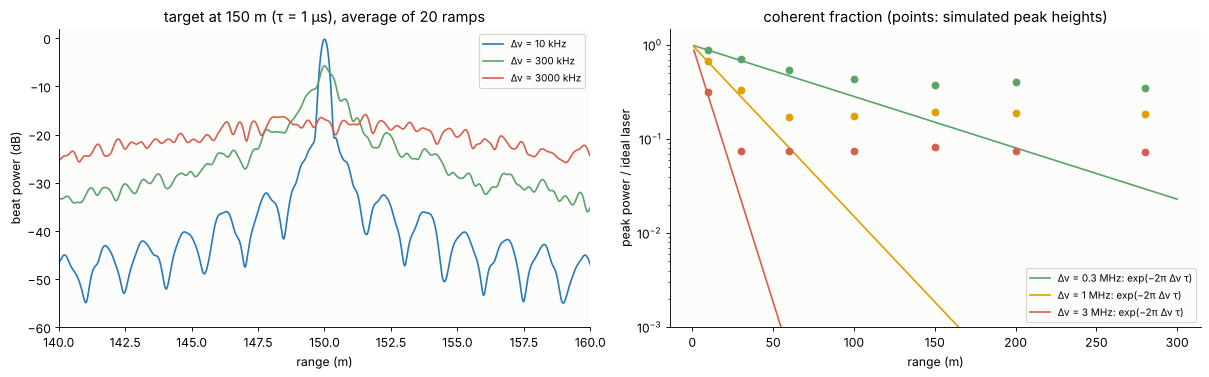

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
for lw, c in ((10e3, BLUE), (300e3, GREEN), (3e6, RED)):
    S_avg = 0
    for seed in range(20):
        b = lidar.fmcw_beat_signal(t, 150.0, B, T, linewidth=lw, rng=seed)
        f, S = spectrum(b)
        S_avg = S_avg + S/20
    axs[0].plot(C*f/(2*KAPPA), 10*np.log10(S_avg), color=c, label="Δν = {:g} kHz".format(lw/1e3))
axs[0].set_xlim(140, 160)
axs[0].set_ylim(-60, 2)
axs[0].set_xlabel("range (m)")
axs[0].set_ylabel("beat power (dB)")
axs[0].set_title("target at 150 m (τ = 1 µs), average of 20 ramps")
axs[0].legend(fontsize=9)

ranges = np.array([10, 30, 60, 100, 150, 200, 280])
for lw, c in ((300e3, GREEN), (1e6, ORANGE), (3e6, RED)):
    peak = []
    for R in ranges:
        S_list = []
        for seed in range(12):
            b = lidar.fmcw_beat_signal(t, R, B, T, linewidth=lw, rng=100 + seed)
            f, S = spectrum(b)
            S_list.append(S.max())
        peak.append(np.mean(S_list))
    axs[1].semilogy(ranges, peak, "o", color=c)
    rr = np.linspace(1, 300, 300)
    axs[1].semilogy(rr, lidar.coherent_fraction(2*rr/C, lw), color=c,
                    label="Δν = {:g} MHz: exp(−2π Δν τ)".format(lw/1e6))
axs[1].set_ylim(1e-3, 1.5)
axs[1].set_xlabel("range (m)")
axs[1].set_ylabel("peak power / ideal laser")
axs[1].set_title("coherent fraction (points: simulated peak heights)")
axs[1].legend(fontsize=9)
plt.show()

At 10 kHz the 150 m peak is as sharp as with an ideal laser; at 300 kHz
the pedestal appears and the peak loses 60 %; at 3 MHz the peak is gone
into a pedestal several metres wide. The simulated peaks (points) follow
$e^{-2\pi\Delta\nu\tau}$ as long as the coherent part dominates; beyond,
they level off: the record of 8 µs resolves 125 kHz, and the part of the
pedestal that falls into the peak's bin, with random phase, keeps a
random peak of that height. Either way the peak no longer stands out
from its own pedestal, which also hides weaker targets nearby. FMCW LiDARs therefore use external cavity or fibre lasers
with linewidths of 10 to 100 kHz, or semiconductor lasers locked to a
narrow line, which makes them more expensive than the pulsed diodes of
ToF LiDARs.

## 6. Nonlinear chirps

The beat frequency is the frequency difference over the delay $\tau$; a
sweep that deviates from a straight line by $\varepsilon(t)$ adds
$\varepsilon(t) - \varepsilon(t-\tau)$ to it, which grows with the range:
near targets stay sharp, far ones smear. A directly modulated
semiconductor laser sweeps with deviations of a per cent of $B$ and
more. Two fixes: predistort the drive current so that the optical sweep
becomes linear, or measure the sweep with a **reference interferometer**
of known delay $\tau_\mathrm{ref}$ and correct the data. The reference
beat's phase is $2\pi\int_{t-\tau_\mathrm{ref}}^{t}\nu\,dt' \approx
2\pi\tau_\mathrm{ref}\,\nu(t - \tau_\mathrm{ref}/2)$: it measures the
optical frequency, its slope $\kappa$ and the deviation $\varepsilon$.

Two corrections are common. **Resampling** the target beat at equal
increments of the measured optical frequency (a "k-clock") linearizes
the phase of targets near the reference delay. For other delays a
skew remains: the target's phase follows $\nu(t-\tau/2)$, not
$\nu(t-\tau_\mathrm{ref}/2)$. The **range dependent phase correction**
multiplies the beat by $\exp(-2\pi i\,[E(t) - E(t-\tau)])$, with
$E = \int\varepsilon\,dt$ from the reference, for the delay $\tau$ of a
coarse first estimate of the peak, and iterates once.

   20 m: peak raw   -6.3 dB, resampled   -0.6 dB, phase corrected  -0.0 dB at +0.006 m
  150 m: peak raw  -12.2 dB, resampled  -13.5 dB, phase corrected  -0.6 dB at +0.030 m


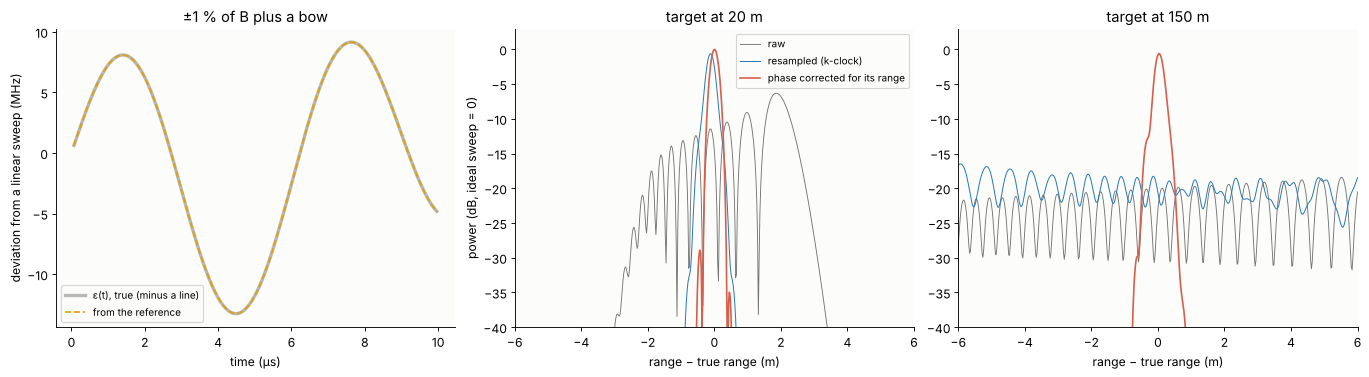

In [10]:
eps = lambda tt: 0.01*B*np.sin(2*np.pi*tt/(0.6*T)) + 0.02*B*((tt/T) - 0.5)**2   # Hz
TAU_REF = 2*10.0/C                      # a 10 m fibre delay (20 m round trip)
t_ref = 0.1e-6 + np.arange(int(9.9e-6*FS))/FS
b_ref = lidar.fmcw_beat_signal(t_ref, 10.0, B, T, nonlinearity=eps)
nu_meas = np.unwrap(np.angle(b_ref))/(2*np.pi*TAU_REF)     # optical frequency up to a constant
t_meas = t_ref - TAU_REF/2
fit = np.polyfit(t_meas, nu_meas, 1)
KAPPA_MEAS = fit[0]
dev = nu_meas - np.polyval(fit, t_meas)                    # measured epsilon (minus a line)
E_cum = np.concatenate([[0.0], np.cumsum(0.5*(dev[1:] + dev[:-1]))/FS])
E_of = lambda x: np.interp(x, t_meas, E_cum)
# k-clock: times of equal optical frequency steps
nu_uniform = np.linspace(nu_meas[0], nu_meas[-1], len(nu_meas))
t_resample = np.interp(nu_uniform, nu_meas, t_meas)
t_resample = t_resample[(t_resample >= t[0]) & (t_resample <= t[-1])][:N]


def range_axis(f, kappa=KAPPA):
    return C*f/(2*kappa)


fig, axs = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
eps_true = eps(t_meas)
axs[0].plot(t_meas*1e6, (eps_true - np.polyval(np.polyfit(t_meas, eps_true, 1), t_meas))/1e6,
            color=GREY, lw=3, alpha=0.5, label="ε(t), true (minus a line)")
axs[0].plot(t_meas*1e6, dev/1e6, color=ORANGE, ls="--", label="from the reference")
axs[0].set_xlabel("time (µs)")
axs[0].set_ylabel("deviation from a linear sweep (MHz)")
axs[0].set_title("±1 % of B plus a bow")
axs[0].legend(fontsize=9)
for ax, R in zip(axs[1:], (20.0, 150.0)):
    b = lidar.fmcw_beat_signal(t, R, B, T, nonlinearity=eps)
    S0 = spectrum(lidar.fmcw_beat_signal(t, R, B, T))[1].max()
    f, S = spectrum(b)
    ax.plot(range_axis(f, KAPPA_MEAS) - R, 10*np.log10(S/S0), color=GREY, lw=0.8, label="raw")
    b_res = np.interp(t_resample, t, b.real) + 1j*np.interp(t_resample, t, b.imag)
    b_res = np.r_[b_res, np.zeros(N - len(b_res))]
    f_r, S_r = spectrum(b_res)
    ax.plot(range_axis(f_r, KAPPA_MEAS) - R, 10*np.log10(S_r/S0), color=BLUE, lw=0.9,
            label="resampled (k-clock)")
    R_c = range_axis(f[np.argmax(S)], KAPPA_MEAS)
    for it in range(2):
        b_c = b*np.exp(-2j*np.pi*(E_of(t) - E_of(t - 2*R_c/C)))
        f_c, S_c = spectrum(b_c)
        R_c = range_axis(f_c[np.argmax(S_c)], KAPPA_MEAS)
    ax.plot(range_axis(f_c, KAPPA_MEAS) - R, 10*np.log10(S_c/S0), color=RED,
            label="phase corrected for its range")
    ax.set_xlim(-6, 6)
    ax.set_ylim(-40, 3)
    ax.set_xlabel("range − true range (m)")
    ax.set_title("target at {:.0f} m".format(R))
    print("{:5.0f} m: peak raw {:6.1f} dB, resampled {:6.1f} dB, phase corrected {:5.1f} dB at "
          "{:+.3f} m".format(R, 10*np.log10(S.max()/S0), 10*np.log10(S_r.max()/S0),
                             10*np.log10(S_c.max()/S0), R_c - R))
axs[1].set_ylabel("power (dB, ideal sweep = 0)")
axs[1].legend(fontsize=9)
plt.show()

The reference interferometer recovers the sweep error to a small
fraction of a MHz. Without correction, the target at 20 m loses 6 dB and
the one at 150 m 12 dB, smeared over metres. Resampling at equal steps
of the optical frequency restores the 20 m target, near the 20 m delay
of the reference, but not the 150 m target, whose phase is skewed by
the difference of the delays. The range dependent phase correction
restores both peaks to within about 1 dB of an ideal sweep and puts
them at the right range: the slope of the sweep is taken from the
reference too, so its calibration is that of the fibre delay. Real
FMCW systems combine predistortion of the laser drive with such digital
corrections.

## Summary

- FMCW turns range into a beat frequency, $f_b = 2\kappa R/c$; the range
  resolution is $c/(2B)$, 15 cm for 1 GHz. An up and a down chirp measure
  range and radial velocity together, a few cm/s per point.
- A balanced coherent receiver with a milliwatt LO reaches the shot
  noise limit: the SNR of a peak is the number of detected signal
  photons in the record. It sees the Sun in one spatial mode only, which
  is practically nothing.
- The same single mode makes the echo of a rough target fade with
  exponential statistics; 99 % detection needs 16 dB more SNR than
  without fading, unless several decorrelated looks are combined.
- The laser's coherence length must exceed twice the range
  (exponential loss $e^{-2\pi\Delta\nu\tau}$), and nonlinear sweeps must be
  measured and corrected, for instance by resampling with a reference
  interferometer.

## References

- P. F. McManamon, *LiDAR Technologies and Systems*, SPIE Press (2019),
  chapters on coherent LiDAR.
- P. J. Winzer and W. R. Leeb, "Coherent lidar at low signal powers:
  basic considerations on optical heterodyning", J. Mod. Opt. 45, 1549
  (1998).
- R. Frehlich and M. J. Kavaya, "Coherent laser radar performance for
  general atmospheric refractive turbulence", Appl. Opt. 30, 5325
  (1991).
- B. Behroozpour, P. A. M. Sandborn, M. C. Wu and B. E. Boser, "Lidar
  system architectures and circuits", IEEE Commun. Mag. 55, 135 (2017).
- E. Baumann, F. R. Giorgetta, I. Coddington, L. C. Sinclair, K. Knabe,
  W. C. Swann and N. R. Newbury, "Comb-calibrated frequency-modulated
  continuous-wave ladar for absolute distance measurements", Opt. Lett.
  38, 2026 (2013).
- M. I. Skolnik, *Introduction to Radar Systems*, 3rd ed., McGraw-Hill
  (2001), for detection with fading targets.

In [11]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 3 s
